# 05 — Mother More Educated Than Father

> **Exploratory analysis.** Our main (confirmatory) analysis is in `03_correlations.ipynb`. The parental education gap was not part of our original hypotheses, so this notebook is **exploratory**. All results are cross-sectional **associations**, based on complete cases and **unweighted** data.

## Purpose

So far we have looked at mother's and father's education separately. In this notebook we look at the **education gap between parents**. One possible reason to expect a link is that a household where the mother is more educated than the father may show children a less traditional division of roles. Our cross-sectional data **cannot test this mechanism**, so throughout this notebook we describe **associations** only. Nothing here shows that having a more educated mother *causes* less traditional attitudes.

Using the grouped parental education levels (Q277R and Q278R), we classify every respondent into one of **three groups**, saved as **`parent_education_gap`**:

- **Mother more educated:** the mother's level is higher than the father's (Q277R > Q278R)
- **Same level:** both parents are at the same level (Q277R = Q278R)
- **Father more educated:** the father's level is higher than the mother's (Q277R < Q278R)
- **Missing:** either parent's education is missing

This three-group variable is our **main analysis**. "Same level" and "father more educated" are substantively different households, so we report them **separately** rather than combining them.

We also keep the binary variable **`mother_more_educated`** (1 = mother more educated, 0 = same level **or** father more educated), because it is used in `07_pca.ipynb`, `06_multivariate_models.ipynb` and `09_sex_differences.ipynb`. Because its "0" group mixes two different kinds of households, we only report it at the end (Section 7) for comparison.

**Important note on the grouped levels:** because we compare *grouped* levels (1 = Lower, 2 = Middle, 3 = Higher), a mother only counts as more educated if she is in a **higher group** than the father. For example, if the mother has a bachelor's degree (ISCED 6) and the father has a short-cycle tertiary diploma (ISCED 5), both are in the "Higher" group, so the mother is **not** counted as more educated. The grouped variable therefore only captures fairly large education gaps. In Section 6 we repeat the main analysis with the **full ISCED levels** (Q277 and Q278, 0–8) as a sensitivity check.

### Analysis plan

1. Compare the three gap groups (Section 4).
2. Compare the groups **within the same level of maternal education** (Section 5). A mother can only be more educated than the father if she has at least middle education, so any raw difference could simply reflect the mother's own education level.
3. Repeat the comparison with the full ISCED levels (Section 6).
4. Report the binary `mother_more_educated` comparison for comparability with the later notebooks (Section 7).

### Hypotheses

**H0c:** Traditional gender-role attitudes do not differ between the three parental education gap groups.

**H1c:** Traditional gender-role attitudes differ between at least two of the gap groups.

As in `03_correlations.ipynb`, the tests are two-tailed because we are testing whether there is a difference, rather than predicting its direction beforehand.

## 1. Setup and Data Loading

We import the same packages as in class and load the cleaned dataset created in `04_reclean_full.ipynb`. From `scipy.stats` we use `ttest_ind` for Welch's independent-samples t-test and `pearsonr` (Week 4), and we use `smf.ols` (Week 5) with categorical predictors (`C()`).

In [1]:
from pathlib import Path  # used to build file paths that work on any computer

import pandas as pd  # data management (DataFrames)
import numpy as np  # numerical tools, e.g. np.nan and np.where
from plotnine import *  # ggplot-style figures, as used in class
from scipy import stats  # statistical tests (t-test and correlation)
import statsmodels.formula.api as smf  # OLS with a categorical predictor (Section 7.1)
import warnings  # lets us silence routine warnings
warnings.filterwarnings('ignore')  # hide warnings so the output is easier to read

In [2]:
# Identify the root folder of the GitHub repository.
PROJECT_ROOT = Path.cwd()  # start from the folder the notebook is running in
if PROJECT_ROOT.name == "code":  # if we are inside the /code folder...
    PROJECT_ROOT = PROJECT_ROOT.parent  # ...move up one level to the repository root

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "WVS_Singapore_full_cleaned.csv"  # cleaned dataset from notebook 04
OUTPUT_FIGURES = PROJECT_ROOT / "output" / "figures"  # folder for saved figures
OUTPUT_TABLES = PROJECT_ROOT / "output" / "tables"  # folder for saved tables

df = pd.read_csv(DATA_PATH)  # load the cleaned dataset

print(f"Number of respondents: {df.shape[0]}")  # number of rows
print(f"Number of variables: {df.shape[1]}")  # number of columns

Number of respondents: 2012
Number of variables: 44


## 2. Comparing Mother's and Father's Education

Before creating the new variable, we cross-tabulate mother's and father's education levels. This shows how often the two parents are in the same group and how often they differ.

In [3]:
edu_labels = {1.0: "Lower", 2.0: "Middle", 3.0: "Higher"}  # labels for the grouped education levels
edu_order = ["Lower", "Middle", "Higher"]  # the order in which the levels should be shown

parents = pd.crosstab(  # count respondents for every combination of mother's and father's education
    df["Q277R"].map(edu_labels), df["Q278R"].map(edu_labels),  # use the labels instead of 1, 2, 3
    rownames=["Mother's education"], colnames=["Father's education"],  # name the rows and columns
).reindex(index=edu_order, columns=edu_order)  # put the levels in order

parents.to_csv(OUTPUT_TABLES / "mother_by_father_education_crosstab.csv")  # save the table
parents  # display the table

Father's education,Lower,Middle,Higher
Mother's education,,,
Lower,1021,182,42
Middle,67,240,86
Higher,8,33,129


In [4]:
both_valid = df[["Q277R", "Q278R"]].dropna()  # respondents who reported both parents' education
rho, p = stats.spearmanr(both_valid["Q277R"], both_valid["Q278R"])  # Spearman correlation between the two (both ordinal)
print(f"N = {len(both_valid)}")  # number of respondents used
print(f"Spearman's rho between mother's and father's education = {rho:.3f}, p-value = {p:.4g}")  # print the result

N = 1808
Spearman's rho between mother's and father's education = 0.687, p-value = 1.702e-252


### Interpretation

The cross-table shows that most respondents' parents were at the **same education level**. The diagonal cells (1,021 + 240 + 129 = **1,390** respondents) are the largest in every row. The most common combination by far is two parents with lower education (**1,021** respondents).

Spearman's rho between mother's and father's education is **ρ = .687** (p < .001, N = 1,808), a **strong positive correlation**. People tended to marry partners with a similar level of education. This matters for the later notebooks: because the two parents' education levels overlap so much, it will be hard to separate the effect of the mother's education from that of the father's when both are in the same regression model. We will check this with variance inflation factors (VIFs) in `06_multivariate_models.ipynb`.

Cells **below** the diagonal are households where the mother is in a higher group than the father (67 + 8 + 33 = **108**), and cells **above** the diagonal are households where the father is in a higher group (182 + 42 + 86 = **310**). Fathers were about three times as likely as mothers to be the more educated parent, which reflects the gender gap in education in the parents' generation.

## 3. Creating the Parental Education Gap Variables

We first create the three-group variable `parent_education_gap` with `np.select`, which assigns a label depending on which condition is true. Respondents with missing education for either parent get the label "Missing", which we then set to `NaN`. This step matters: comparing a missing value always gives `False`, so without it these respondents would not be placed correctly.

We then derive the binary `mother_more_educated` from it (1 = mother more educated, 0 = the other two groups, missing if `parent_education_gap` is missing).

In [5]:
gap_order = ["Mother more educated", "Same level", "Father more educated"]  # the three gap groups
gap = np.select(  # assign one of three labels depending on which parent has the higher level
    [df["Q277R"] > df["Q278R"], df["Q277R"] == df["Q278R"], df["Q277R"] < df["Q278R"]],  # the three conditions
    gap_order, default="Missing")  # the matching labels; "Missing" if either parent's education is missing

df["mother_more_educated"] = np.where(gap == "Mother more educated", 1.0, 0.0)  # binary version: 1 = mother more educated
df.loc[gap == "Missing", "mother_more_educated"] = np.nan  # missing if either parent's education is missing
df["parent_education_gap"] = pd.Series(gap, index=df.index).replace("Missing", np.nan)  # three-group variable

counts = df["parent_education_gap"].fillna("Missing (either parent)").value_counts().reindex(  # count each group...
    gap_order + ["Missing (either parent)"])  # ...in a fixed order
group_table = pd.DataFrame({  # build a frequency table
    "Frequency": counts,  # number of respondents
    "Percentage of full sample (%)": (counts / len(df) * 100).round(1),  # percentage of all 2,012 respondents
    "Percentage of valid cases (%)": (counts / df["parent_education_gap"].notna().sum() * 100).round(1),  # % of non-missing
    "mother_more_educated": [1, 0, 0, np.nan],  # how each group is coded in the binary variable
})
group_table.loc["Missing (either parent)", "Percentage of valid cases (%)"] = np.nan  # this percentage does not apply to missing

group_table.to_csv(OUTPUT_TABLES / "parent_education_gap_distribution.csv")  # save the table
group_table  # display the table

,Frequency,Percentage of full sample (%),Percentage of valid cases (%),mother_more_educated
parent_education_gap,,,,
Mother more educated,108,5.4,6.0,1.0
Same level,1390,69.1,76.9,0.0
Father more educated,310,15.4,17.1,0.0
Missing (either parent),204,10.1,NaN,NaN


### Interpretation

Out of the **1,808** respondents who reported both parents' education:

- **1,390 (76.9%)** have parents at the **same level**;
- **310 (17.1%)** have a **father who is more educated**;
- **108 (6.0%)** have a **mother who is more educated**.

**204 respondents (10.1% of the full sample)** are missing because the education of at least one parent was not reported.

In the binary `mother_more_educated` variable, the 1,390 same-level and 310 father-more-educated respondents are all coded **0**. These are very different households, which is why our main analysis keeps the three groups apart.

The "mother more educated" group is **very small**. This has two consequences:

1. Any estimate for this group is based on only about 100 people, so it will be less precise, and the tests have less power to detect small differences.
2. Because we compare grouped levels, smaller education gaps within the same group are not counted, which partly explains why the group is so small (see Section 6).

## 4. Main Analysis: Comparing the Three Gap Groups

We describe traditional gender-role attitudes in each of the three groups and show the distributions with a boxplot, as in `03_correlations.ipynb`. We then test the overall difference with an OLS model using `C()` (equivalent to a one-way ANOVA), with **same level** as the reference group, and compare each pair of groups with **Welch's t-test** and **Cohen's d**.

We did not run a t-test in class, so we briefly explain it here:

- The t-test asks whether the difference between two group means is larger than we would expect by chance if the true population means were equal.
- We use **Welch's version** (`equal_var=False`), which does not assume that the two groups have the same variance. This is the safer choice here because the groups are very different in size.
- **Cohen's d** expresses the difference between the means in standard-deviation units. As a rough guide, d ≈ 0.2 is a small effect, 0.5 medium and 0.8 large.

In [6]:
gap_data = df.dropna(subset=["parent_education_gap", "traditional_gender_attitudes"]).copy()  # complete cases

gap_desc = (gap_data.groupby("parent_education_gap")["traditional_gender_attitudes"]  # scores by gap group
            .agg(["count", "mean", "std", "median"]).reindex(gap_order))  # descriptive statistics in a fixed order
gap_desc.to_csv(OUTPUT_TABLES / "parent_education_gap_descriptives.csv")  # save the table
gap_desc.round(3)  # display the table

,count,mean,std,median
parent_education_gap,,,,
Mother more educated,104,1.906,0.534,2.0
Same level,1365,2.140,0.554,2.0
Father more educated,304,2.021,0.559,2.0


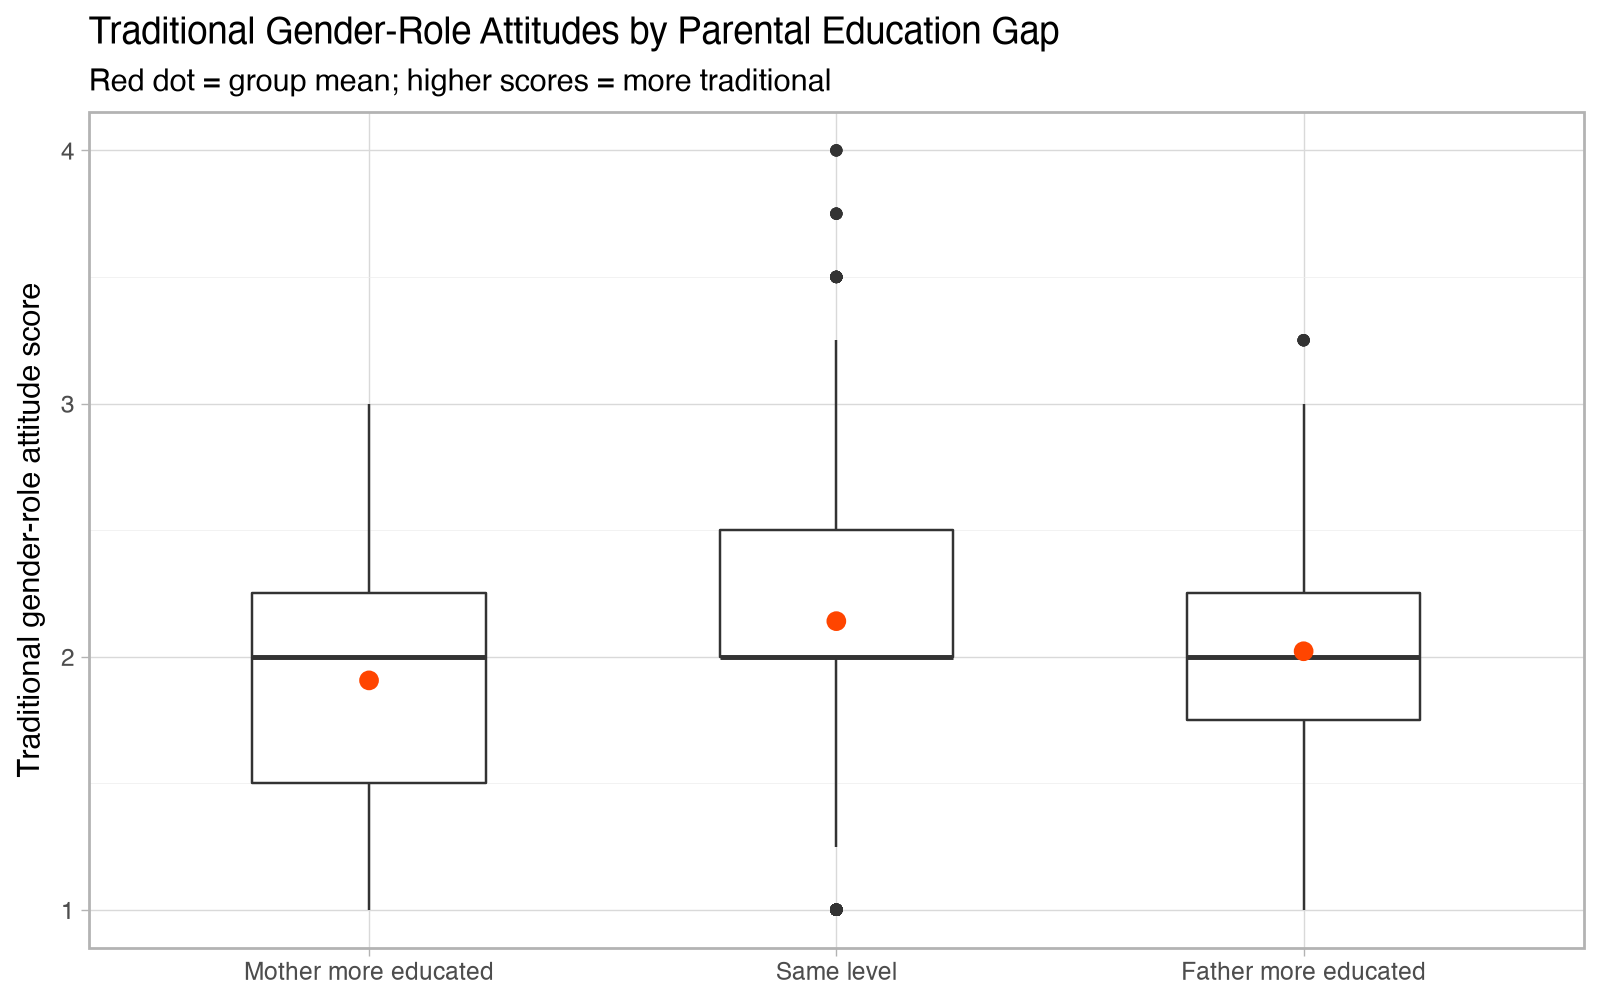

In [7]:
gap_data["Gap group"] = pd.Categorical(gap_data["parent_education_gap"], gap_order)  # fixed order for the plot
p = (
    ggplot(gap_data, aes(x="Gap group", y="traditional_gender_attitudes"))  # x = gap group, y = gender-role score
    + geom_boxplot(width=0.5)  # draw a boxplot for each group
    + stat_summary(fun_y=np.mean, geom="point", color="orangered", size=3)  # add the group mean as a red dot
    + theme_light()  # clean background, as in class
    + labs(x="", y="Traditional gender-role attitude score",  # axis labels
           title="Traditional Gender-Role Attitudes by Parental Education Gap",  # title
           subtitle="Red dot = group mean; higher scores = more traditional")  # subtitle
    + theme(figure_size=(8, 5))  # figure size
)
p.save(OUTPUT_FIGURES / "parent_education_gap_gender_attitudes_boxplot.png", dpi=300, verbose=False)  # save the figure
p  # display the figure

In [8]:
gap_model = smf.ols("traditional_gender_attitudes ~ C(parent_education_gap, Treatment('Same level'))", data=gap_data).fit()  # three groups
print(f"Overall F = {gap_model.fvalue:.3f}, p-value = {gap_model.f_pvalue:.4g}")  # do the three groups differ?
print(gap_model.summary().tables[1])  # each group compared with 'Same level'


def compare(a, b):
    # Welch's t-test and Cohen's d for two of the gap groups.
    x = gap_data.loc[gap_data["parent_education_gap"] == a, "traditional_gender_attitudes"]  # scores in group a
    y = gap_data.loc[gap_data["parent_education_gap"] == b, "traditional_gender_attitudes"]  # scores in group b
    t, p = stats.ttest_ind(x, y, equal_var=False)  # Welch's t-test
    sd = np.sqrt(((len(x) - 1) * x.var() + (len(y) - 1) * y.var()) / (len(x) + len(y) - 2))  # pooled SD
    return {"Comparison": f"{a} vs {b}", "Mean difference": x.mean() - y.mean(), "Welch's t": t, "p-value": p,
            "Cohen's d": (x.mean() - y.mean()) / sd}


pairs = pd.DataFrame([compare("Mother more educated", "Same level"), compare("Father more educated", "Same level"),
                      compare("Mother more educated", "Father more educated")])  # all three pairs
pairs.to_csv(OUTPUT_TABLES / "parent_education_gap_comparisons.csv", index=False)  # save the table
pairs.round(4)  # display the table

Overall F = 12.950, p-value = 2.609e-06
                                                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                    2.1403      0.015    142.896      0.000       2.111       2.170
C(parent_education_gap, Treatment('Same level'))[T.Father more educated]    -0.1189      0.035     -3.388      0.001      -0.188      -0.050
C(parent_education_gap, Treatment('Same level'))[T.Mother more educated]    -0.2340      0.056     -4.158      0.000      -0.344      -0.124


,Comparison,Mean difference,Welch's t,p-value,Cohen's d
0,Mother more educated vs Same level,-0.2340,-4.2954,0.0000,-0.4239
1,Father more educated vs Same level,-0.1189,-3.3594,0.0008,-0.2144
2,Mother more educated vs Father more educated,-0.1151,-1.8744,0.0624,-0.2082


### Interpretation

**The three groups.** The **same-level** group is the **most traditional** (M = 2.140, n = 1,365), the **father-more-educated** group is in between (M = 2.021, n = 304) and the **mother-more-educated** group is the least traditional (M = 1.906, n = 104). The three groups differ significantly overall (F = 12.95, p < .001), so we **reject H0c**. The boxplot shows that the distributions overlap a lot. The differences are modest shifts, not a clear separation between the groups.

**Pairwise comparisons:**
- **Mother more educated vs. same level:** −0.234 points (Welch's t = −4.30, p < .001, d = −0.42, a small-to-medium difference).
- **Father more educated vs. same level:** −0.119 points (t = −3.36, p < .001, d = −0.21). So the father-more-educated families, which are hidden in the "0" group of the binary variable, are *also* less traditional than same-level families.
- **Mother more educated vs. father more educated:** −0.115 points (t = −1.87, **p = .062**, d = −0.21). This difference is **not statistically significant** at α = .05.

**Why is the same-level group the most traditional?** Most same-level families are families where **both** parents had lower education (1,021 of 1,390), so this group mostly reflects low overall parental education. Any family with an education gap must have at least one parent above the lowest level. These raw differences therefore mix the **gap** between the parents with the parents' **absolute** education levels. Section 5 separates the two.

## 5. Holding Maternal Education Comparable

This is the most important check in this notebook. Respondents whose mother is more educated than their father must, by definition, have a mother with at least middle education. Since we already know from `03_correlations.ipynb` that more educated mothers are linked to less traditional attitudes, the raw "mother more educated" difference in Section 4 could simply reflect the **mother's own education level** rather than the **gap** between the parents.

We therefore compare the gap groups **among respondents whose mothers are at the same education level**. For example, among mothers with higher education, we compare respondents whose father was less educated with those whose father was equally educated. We do this in three steps:

1. Descriptive statistics for each gap group within each level of mother's education.
2. Welch's t-tests and Cohen's d **within** the middle and higher maternal education levels. (A mother with lower education can never be more educated than the father, so the "mother more educated" group does not exist at that level.)
3. An OLS model with the gap groups and mother's education level as a category, `C(Q277R)`. This gives one combined estimate of each gap group's difference from the same-level group **among respondents whose mothers have the same education level**.

In [9]:
within_mother = (gap_data.assign(mother_level=lambda x: pd.Categorical(x["Q277R"].map(edu_labels), edu_order))  # mother's level
                 .groupby(["mother_level", "Gap group"], observed=True)["traditional_gender_attitudes"]  # by mother's level and gap
                 .agg(["count", "mean", "std"]))  # descriptive statistics
within_mother.to_csv(OUTPUT_TABLES / "parent_education_gap_within_mother_level.csv")  # save the table
within_mother.round(3)  # display the table

count   mean    std
mother_level Gap group                                
Lower        Same level             1002  2.189  0.521
             Father more educated    220  2.040  0.532
Middle       Mother more educated     63  1.996  0.528
             Same level              236  2.090  0.574
             Father more educated     84  1.973  0.626
Higher       Mother more educated     41  1.768  0.520
             Same level              127  1.846  0.662

In [10]:
def compare_groups(data, a, b, label):
    # Welch's t-test and Cohen's d for gap group a versus gap group b within one subset of respondents.
    x = data.loc[data["parent_education_gap"] == a, "traditional_gender_attitudes"]  # scores in group a
    y = data.loc[data["parent_education_gap"] == b, "traditional_gender_attitudes"]  # scores in group b
    t, p = stats.ttest_ind(x, y, equal_var=False)  # Welch's t-test
    sd = np.sqrt(((len(x) - 1) * x.var() + (len(y) - 1) * y.var()) / (len(x) + len(y) - 2))  # pooled SD
    return {"Mother's education": label, "Comparison": f"{a} vs {b}", "n (a)": len(x), "n (b)": len(y),
            "Mean difference": x.mean() - y.mean(), "Welch's t": t, "p-value": p, "Cohen's d": (x.mean() - y.mean()) / sd}


middle = gap_data[gap_data["Q277R"] == 2]  # respondents whose mother had middle education
higher = gap_data[gap_data["Q277R"] == 3]  # respondents whose mother had higher education
lower = gap_data[gap_data["Q277R"] == 1]  # respondents whose mother had lower education
within_tests = pd.DataFrame([
    compare_groups(middle, "Mother more educated", "Same level", "Middle"),  # father lower vs father middle
    compare_groups(higher, "Mother more educated", "Same level", "Higher"),  # father lower/middle vs father higher
    compare_groups(lower, "Father more educated", "Same level", "Lower"),  # father middle/higher vs father lower
    compare_groups(middle, "Father more educated", "Same level", "Middle"),  # father higher vs father middle
])
within_tests.to_csv(OUTPUT_TABLES / "parent_education_gap_within_mother_tests.csv", index=False)  # save the table
within_tests.round(4)  # display the table

,Mother's education,Comparison,n (a),n (b),Mean difference,Welch's t,p-value,Cohen's d
0,Middle,Mother more educated vs Same level,63,236,-0.0940,-1.2315,0.2209,-0.1665
1,Higher,Mother more educated vs Same level,41,127,-0.0782,-0.7802,0.4374,-0.1239
2,Lower,Father more educated vs Same level,220,1002,-0.1496,-3.7918,0.0002,-0.2862
3,Middle,Father more educated vs Same level,84,236,-0.1168,-1.5011,0.1357,-0.1987


In [11]:
raw_model = smf.ols("traditional_gender_attitudes ~ C(parent_education_gap, Treatment('Same level'))", data=gap_data).fit()  # Section 4
within_model = smf.ols("traditional_gender_attitudes ~ C(parent_education_gap, Treatment('Same level')) + C(Q277R)",
                       data=gap_data).fit()  # same model, holding mother's education level constant
print(within_model.summary().tables[1])  # coefficient table

terms = {"Mother more educated": "C(parent_education_gap, Treatment('Same level'))[T.Mother more educated]",
         "Father more educated": "C(parent_education_gap, Treatment('Same level'))[T.Father more educated]"}
shrinkage = pd.DataFrame({  # raw versus within-maternal-education differences from the same-level group
    "Raw difference": [raw_model.params[t] for t in terms.values()],
    "p (raw)": [raw_model.pvalues[t] for t in terms.values()],
    "Same mother's level": [within_model.params[t] for t in terms.values()],
    "p (same mother's level)": [within_model.pvalues[t] for t in terms.values()],
}, index=[f"{g} vs Same level" for g in terms])
shrinkage["% of raw difference remaining"] = (shrinkage["Same mother's level"] / shrinkage["Raw difference"] * 100).round(0)
shrinkage.to_csv(OUTPUT_TABLES / "parent_education_gap_raw_vs_within_mother.csv")  # save the table
shrinkage.round(4)  # display the table

                                                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                    2.1878      0.017    129.975      0.000       2.155       2.221
C(parent_education_gap, Treatment('Same level'))[T.Father more educated]    -0.1408      0.035     -4.026      0.000      -0.209      -0.072
C(parent_education_gap, Treatment('Same level'))[T.Mother more educated]    -0.0921      0.060     -1.536      0.125      -0.210       0.025
C(Q277R)[T.2.0]                                                             -0.0928      0.034     -2.769      0.006      -0.159      -0.027
C(Q277R)[T.3.0]                                                             -0.3379      0.047     -7.120      0.000      -0.431      -0.245


,Raw difference,p (raw),Same mother's level,p (same mother's level),% of raw difference remaining
Mother more educated vs Same level,-0.2340,0.0000,-0.0921,0.1247,39.0
Father more educated vs Same level,-0.1189,0.0007,-0.1408,0.0001,118.0


In [12]:
gap_levels = smf.ols("traditional_gender_attitudes ~ C(parent_education_gap, Treatment('Same level')) + Q277R + Q278R",
                     data=gap_data).fit()  # gap groups plus both parents' education levels
print(gap_levels.summary().tables[1])  # coefficient table

                                                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                    2.3446      0.033     71.724      0.000       2.280       2.409
C(parent_education_gap, Treatment('Same level'))[T.Father more educated]     0.0163      0.102      0.160      0.873      -0.183       0.216
C(parent_education_gap, Treatment('Same level'))[T.Mother more educated]    -0.2189      0.107     -2.043      0.041      -0.429      -0.009
Q277R                                                                       -0.0199      0.085     -0.233      0.816      -0.187       0.147
Q278R                                                                       -0.1305      0.085     -1.543      0.123      -0.296       0.035


### Interpretation

**Within each level of maternal education, the "mother more educated" difference shrinks considerably and is no longer statistically significant:**

| Mother's education | Mother more educated | Same level | Difference | Welch's t (p) | Cohen's d |
|---|---|---|---|---|---|
| **Middle** (father lower vs. father middle) | 1.996 (n = 63) | 2.090 (n = 236) | −0.094 | −1.23 (p = .221) | −0.17 |
| **Higher** (father lower/middle vs. father higher) | 1.768 (n = 41) | 1.846 (n = 127) | −0.078 | −0.78 (p = .437) | −0.12 |

In both cases the "mother more educated" group is still slightly less traditional, but the difference is only **0.08–0.09 points**, compared with the raw difference of 0.234 in Section 4. The effect sizes are small (d = −0.12 to −0.17), and the subgroups are small, so the tests have limited power.

**The combined model tells the same story.** Holding mother's education level constant, the mother-more-educated group differs from the same-level group by only **−0.092 points (p = .125)**, about **40%** of the raw difference (−0.234, p < .001). In other words, **most of the raw difference reflects the mother's own, absolute education level**, not the fact that she was more educated *than the father*. After this adjustment we have no reliable evidence of an additional association with the mother being the more educated parent.

**The father-more-educated group behaves differently.** Holding mother's level constant, it remains less traditional than the same-level group (−0.141, p < .001). This is mainly driven by mothers with lower education (2.040 vs. 2.189, see the test table), where a father with more education than the mother is linked to less traditional attitudes. This is consistent with the association with **father's** education that we found in `03_correlations.ipynb`, rather than with an effect of the gap itself.

**With both parents' education levels in the model** (last table), the father-more-educated group no longer differs from the same-level group (b = +0.016, p = .873), while the mother-more-educated group is somewhat less traditional (b = −0.219, p = .041). This model should be read with care. The gap groups are fully determined by the two parents' levels, so this coefficient does **not** show the effect of changing the gap with both levels held fixed. It shows that the specific combinations where the mother is in a higher group sit slightly below what a straight-line (numeric) model of the two parents' levels predicts. The within-level comparisons above are easier to interpret, and they show only a small, non-significant difference.

**Conclusion:** the raw association between having a more educated mother and less traditional attitudes is mostly explained by the mother's absolute education level. Any additional association specific to the mother being the more educated parent is small and uncertain.

## 6. Sensitivity Check: Full ISCED Education Levels

The grouped variables (Q277R and Q278R) only distinguish three levels, so smaller education differences between the parents are missed. For example, ISCED 5 vs. 6 (short-cycle tertiary vs. bachelor's) or ISCED 0 vs. 2 (no education vs. lower secondary) both count as "same level". We now repeat the main analysis with the **full ISCED levels (Q277 and Q278, 0–8)**, which `04_reclean_full.ipynb` imported with the correct column alignment.

This version has its own limitation: ISCED levels are not equally spaced, so a one-level difference does not always mean the same amount of extra education (e.g. ISCED 3 vs. 4 is a smaller step than ISCED 4 vs. 5). We therefore use it **only** as a check on the grouped results.

We compare the three ISCED-based gap groups (1) without adjustment, (2) holding mother's ISCED level constant with `C(Q277)`, as in Section 5, and (3) with both parents' ISCED levels in the model.

In [13]:
isced = df.dropna(subset=["Q277", "Q278", "traditional_gender_attitudes"]).copy()  # complete cases on the ISCED variables
isced["gap_isced"] = np.select([isced["Q277"] > isced["Q278"], isced["Q277"] == isced["Q278"]],  # mother higher / same
                               ["Mother more educated", "Same level"], default="Father more educated")  # otherwise father higher

print("How respondents move between the grouped and the ISCED gap groups (rows = ISCED, columns = grouped):")
print(pd.crosstab(isced["gap_isced"], isced["parent_education_gap"].fillna("Missing (grouped)")).reindex(gap_order))

isced_desc = isced.groupby("gap_isced")["traditional_gender_attitudes"].agg(["count", "mean", "std"]).reindex(gap_order)
isced_desc.to_csv(OUTPUT_TABLES / "parent_education_gap_isced_descriptives.csv")  # save the table
isced_desc.round(3)  # display the table

How respondents move between the grouped and the ISCED gap groups (rows = ISCED, columns = grouped):
parent_education_gap  Father more educated  Mother more educated  Same level
gap_isced                                                                   
Mother more educated                     0                   104          69
Same level                               0                     0        1089
Father more educated                   304                     0         207


,count,mean,std
gap_isced,,,
Mother more educated,173,1.957,0.571
Same level,1089,2.161,0.542
Father more educated,511,2.040,0.568


In [14]:
isced_specs = {  # the three models
    "Raw": "traditional_gender_attitudes ~ C(gap_isced, Treatment('Same level'))",
    "Same mother's ISCED level": "traditional_gender_attitudes ~ C(gap_isced, Treatment('Same level')) + C(Q277)",
    "Both parents' ISCED levels": "traditional_gender_attitudes ~ C(gap_isced, Treatment('Same level')) + Q277 + Q278",
}
isced_rows = []  # list to collect the results
for spec, formula in isced_specs.items():  # fit each model
    model = smf.ols(formula, data=isced).fit()
    for group in ["Mother more educated", "Father more educated"]:  # each gap group vs same level
        term = f"C(gap_isced, Treatment('Same level'))[T.{group}]"
        isced_rows.append({"Model": spec, "Comparison": f"{group} vs Same level", "N": int(model.nobs),
                           "b": model.params[term], "p-value": model.pvalues[term]})

isced_results = pd.DataFrame(isced_rows)  # combine into a table
isced_results.to_csv(OUTPUT_TABLES / "parent_education_gap_isced_models.csv", index=False)  # save the table
isced_results.round(4)  # display the table

,Model,Comparison,N,b,p-value
0,Raw,Mother more educated vs Same level,1773,-0.2045,0.0000
1,Raw,Father more educated vs Same level,1773,-0.1215,0.0000
2,Same mother's ISCED level,Mother more educated vs Same level,1773,-0.0855,0.0782
3,Same mother's ISCED level,Father more educated vs Same level,1773,-0.1159,0.0001
4,Both parents' ISCED levels,Mother more educated vs Same level,1773,-0.1425,0.0116
5,Both parents' ISCED levels,Father more educated vs Same level,1773,-0.0156,0.7521


### Interpretation

With the full ISCED levels, more respondents have parents at **different** levels: **173** have a more educated mother (instead of 104) and **511** a more educated father (instead of 304). The extra cases come from the grouped "same level" category (69 move to "mother more educated" and 207 to "father more educated"). No respondent switches between "mother more educated" and "father more educated".

The pattern is the **same as with the grouped levels**:

- **Raw comparison:** same-level families are the most traditional (M = 2.161), followed by father-more-educated (M = 2.040) and mother-more-educated families (M = 1.957). The mother-more-educated group is 0.205 points less traditional than the same-level group (p < .001), similar to the grouped result (−0.234).
- **Holding mother's ISCED level constant:** the mother-more-educated difference shrinks to **−0.086 (p = .078)**, about 40% of the raw difference and not significant, just as in Section 5 (−0.092, p = .125). The father-more-educated difference stays similar (−0.116, p < .001).
- **With both parents' ISCED levels in the model:** the mother-more-educated group is again somewhat less traditional (b = −0.143, p = .012) and the father-more-educated group does not differ (b = −0.016, p = .75). As in Section 5, this coefficient reflects a departure from the straight-line pattern of the two parents' levels, not the effect of changing the gap with both levels fixed.

So capturing smaller education differences does **not** change our conclusions. The raw "mother more educated" difference is mostly explained by the mother's own education level.

## 7. The Binary Variable `mother_more_educated` (for Comparison)

The later notebooks (`07_pca.ipynb`, `06_multivariate_models.ipynb` and `09_sex_differences.ipynb`) use the binary `mother_more_educated`, so we also report its comparison here. Its "0" group combines **same-level** and **father-more-educated** families, which Section 4 showed differ from each other (M = 2.140 vs. 2.021). The binary comparison is therefore harder to interpret than the three-group comparison, and the results below should be read alongside Sections 4–6.

**H₀: μ(mother more educated) = μ(same level or father more educated)**

**H₁: μ(mother more educated) ≠ μ(same level or father more educated)**

We use Welch's t-test and Cohen's d, as in Section 4.

In [15]:
test_data = df.dropna(subset=["mother_more_educated", "traditional_gender_attitudes"]).copy()  # complete cases for this test
test_data["group"] = test_data["mother_more_educated"].map({1.0: "Mother more educated", 0.0: "Same level or father more educated"})  # labels

group_desc = (test_data.groupby("group")["traditional_gender_attitudes"]  # group the scores by the binary variable
              .agg(["count", "mean", "std", "median"])  # calculate the descriptive statistics
              .reindex(["Same level or father more educated", "Mother more educated"]))  # fixed order of the rows

group_desc.to_csv(OUTPUT_TABLES / "mother_more_educated_gender_attitudes_descriptives.csv")  # save the table
group_desc.round(3)  # display the table

,count,mean,std,median
group,,,,
Same level or father more educated,1669,2.119,0.556,2.0
Mother more educated,104,1.906,0.534,2.0


In [16]:
group1 = test_data.loc[test_data["mother_more_educated"] == 1, "traditional_gender_attitudes"]  # scores: mother more educated
group0 = test_data.loc[test_data["mother_more_educated"] == 0, "traditional_gender_attitudes"]  # scores: same level or father more

t_stat, t_p = stats.ttest_ind(group1, group0, equal_var=False)  # Welch's independent-samples t-test

pooled_sd = np.sqrt(((len(group1) - 1) * group1.var() + (len(group0) - 1) * group0.var())  # pooled standard deviation
                    / (len(group1) + len(group0) - 2))
cohens_d = (group1.mean() - group0.mean()) / pooled_sd  # Cohen's d: mean difference in SD units

print(f"N (mother more educated) = {len(group1)}, N (same level or father more educated) = {len(group0)}")  # group sizes
print(f"Mean difference (1 - 0) = {group1.mean() - group0.mean():.3f}")  # difference between the group means
print(f"Welch's t = {t_stat:.3f}, p-value = {t_p:.4g}")  # test statistic and p-value
print(f"Cohen's d = {cohens_d:.3f}")  # effect size

N (mother more educated) = 104, N (same level or father more educated) = 1669
Mean difference (1 - 0) = -0.212
Welch's t = -3.924, p-value = 0.0001474
Cohen's d = -0.383


### Interpretation

Respondents whose mother is more educated than their father have a lower mean score (**M = 1.906**, SD = 0.534, n = 104) than all other respondents (**M = 2.119**, SD = 0.556, n = 1,669). Welch's t-test shows that this difference is **statistically significant**, **t = −3.924, p < .001**, and Cohen's d is **−0.383**, a small-to-medium difference.

This binary result sits between the two comparisons in Section 4: the "0" group averages the more traditional same-level families (M = 2.140) and the less traditional father-more-educated families (M = 2.021). It is a difference between groups of respondents, and it does **not** show that having a more educated mother *causes* less traditional attitudes. As Section 5 showed, most of this raw difference reflects the mother's own education level: among respondents whose mothers are at the same level, the difference is only about 0.08–0.09 points and not significant.

### 7.1 Supplementary: Point-Biserial Correlation

For completeness we also report the correlation between `mother_more_educated` and the gender-role score. When one variable is binary (0/1), the Pearson correlation from class (`stats.pearsonr`) is called the **point-biserial correlation**. It is mathematically equivalent to the t-test above, so it adds **no new evidence**. We only report it so that the strength of the association can be compared with the Spearman correlations in `03_correlations.ipynb`.

In [17]:
r, r_p = stats.pearsonr(test_data["mother_more_educated"], test_data["traditional_gender_attitudes"])  # point-biserial r

print(f"N = {len(test_data)}")  # number of respondents used
print(f"Point-biserial r = {r:.3f}, p-value = {r_p:.4g}")  # correlation and p-value

results = pd.DataFrame({  # collect the results into one table
    "Test": ["Welch's t-test", "Point-biserial correlation"],  # test names
    "N": [len(test_data), len(test_data)],  # sample size
    "Statistic": [t_stat, r],  # t value and r value
    "p-value": [t_p, r_p],  # p-values
    "Effect size": [f"Cohen's d = {cohens_d:.3f}", f"r = {r:.3f}"],  # effect sizes
})
results.to_csv(OUTPUT_TABLES / "mother_more_educated_tests.csv", index=False)  # save the table

N = 1773
Point-biserial r = -0.090, p-value = 0.000158


### Interpretation

The point-biserial correlation is **r = −.090, p < .001** (N = 1,773), a very weak negative association. It is much smaller than Cohen's d (−0.383) only because just 6% of respondents are in the "mother more educated" group: a variable that applies to very few people cannot line up with much of the variation in the whole sample. The t-test and Cohen's d above are the more informative summary, so we do not use this correlation in our conclusions.

## 8. Saving the Variables to the Cleaned Dataset

Finally, we save `mother_more_educated` and `parent_education_gap` into the cleaned dataset (`WVS_Singapore_full_cleaned.csv`), so the later notebooks can use them. The file is overwritten with the same data plus the new columns. Re-running this notebook simply recreates the same columns. The ISCED-based gap groups from Section 6 are only used as a sensitivity check and are not saved.

In [18]:
df.to_csv(DATA_PATH, index=False)  # save the dataset, now including mother_more_educated

check = pd.read_csv(DATA_PATH)  # reload the file to check that the variable was saved
print(f"mother_more_educated saved: {'mother_more_educated' in check.columns}")  # confirm the column exists
print(f"parent_education_gap saved: {'parent_education_gap' in check.columns}")  # confirm the three-group variable exists
print(check["mother_more_educated"].value_counts(dropna=False).sort_index())  # confirm the counts match the table above

mother_more_educated saved: True
parent_education_gap saved: True
mother_more_educated
0.0    1700
1.0     108
NaN     204
Name: count, dtype: int64


## Summary

- We classified respondents into **three parental education gap groups** (`parent_education_gap`): **same level** (1,390, 76.9% of valid cases), **father more educated** (310, 17.1%) and **mother more educated** (108, 6.0%). 204 respondents are missing. The binary `mother_more_educated` (1 = mother more educated, 0 = the other two groups) is kept for the later notebooks.
- **Raw comparison:** same-level families are the most traditional (M = 2.140), father-more-educated families are in between (M = 2.021) and mother-more-educated families are the least traditional (M = 1.906). The groups differ significantly (F = 12.95, p < .001). The mother-more-educated and father-more-educated groups do **not** differ significantly from each other (p = .062).
- **Holding maternal education comparable (the key result):** among respondents whose mothers are at the same education level, the mother-more-educated group is only 0.08–0.09 points less traditional than the same-level group (both p > .2). In the combined model the difference shrinks from **−0.234 to −0.092 (p = .125)**. Most of the raw difference therefore reflects the **mother's own education level**, not the gap between the parents.
- **Full ISCED levels:** capturing smaller education differences gives the same pattern (raw −0.205, p < .001; holding mother's ISCED level constant −0.086, p = .078).
- **Binary comparison:** `mother_more_educated` = 1 vs. 0 gives M = 1.906 vs. 2.119 (Welch's t = −3.924, p < .001, Cohen's d = −0.383), but this comparison mixes two different reference groups and mostly reflects mothers' absolute education.

**Limitations:** this is a cross-sectional **association**, so we cannot say that having a more educated mother *causes* less traditional attitudes. Parental education is reported by the respondents. The grouped levels miss smaller education gaps, and the ISCED levels are not equally spaced. The "mother more educated" group is small (104 respondents in the analyses), so its estimates are imprecise and the within-level tests have limited power. The gap groups are fully determined by the two parents' education levels, so their separate contribution cannot be cleanly isolated in a regression.